In [1]:
import sys, json
from pathlib import Path
p = Path.cwd()
while not (p / "data.py").exists():
    p = p.parent
sys.path.insert(0, str(p))

import numpy as np
from data import get_splits
from metrics import evaluate
from final_models import MODELS

saved = json.load(open(p / "results" / "metrics.json"))
d = get_splits()
print({k: v.shape for k, v in d.items()})

{'X_train': (50000, 784), 'y_train': (50000,), 'X_val': (10000, 784), 'y_val': (10000,), 'X_test': (10000, 784), 'y_test': (10000,)}


In [2]:
rows = []
for name, fit in MODELS.items():
    predict = fit(d)
    r = evaluate(d["y_val"], predict(d["X_val"]))
    old = saved[name]["val"]["accuracy"]
    rows.append((name, r["accuracy"] * 100, old * 100, (r["accuracy"] - old) * 100))
    print(f"{name:14s} | val tái tạo {r['accuracy']*100:.2f}% | đã lưu {old*100:.2f}% | lệch {(r['accuracy']-old)*100:+.2f}")

GaussianNB     | val tái tạo 79.78% | đã lưu 79.78% | lệch +0.00
MultinomialNB  | val tái tạo 82.38% | đã lưu 82.38% | lệch +0.00
BernoulliNB    | val tái tạo 83.53% | đã lưu 83.53% | lệch +0.00
Softmax        | val tái tạo 92.02% | đã lưu 92.02% | lệch +0.00
MLP            | val tái tạo 97.85% | đã lưu 97.85% | lệch +0.00
RandomForest   | val tái tạo 96.15% | đã lưu 96.15% | lệch +0.00


In [3]:
print("| Mô hình | Train | Val | Test | Test F1 macro |")
print("|---|---|---|---|---|")
for n in saved:
    a = {s: saved[n][s]["accuracy"] * 100 for s in ["train", "val", "test"]}
    print(f"| {n} | {a['train']:.2f} | {a['val']:.2f} | {a['test']:.2f} | {saved[n]['test']['f1_macro']*100:.2f} |")

| Mô hình | Train | Val | Test | Test F1 macro |
|---|---|---|---|---|
| GaussianNB | 80.29 | 79.78 | 81.59 | 81.44 |
| MultinomialNB | 82.55 | 82.38 | 83.74 | 83.60 |
| BernoulliNB | 83.82 | 83.53 | 84.50 | 84.32 |
| Softmax | 92.87 | 92.02 | 92.31 | 92.20 |
| MLP | 99.95 | 97.85 | 98.13 | 98.12 |
| RandomForest | 99.91 | 96.15 | 96.21 | 96.17 |


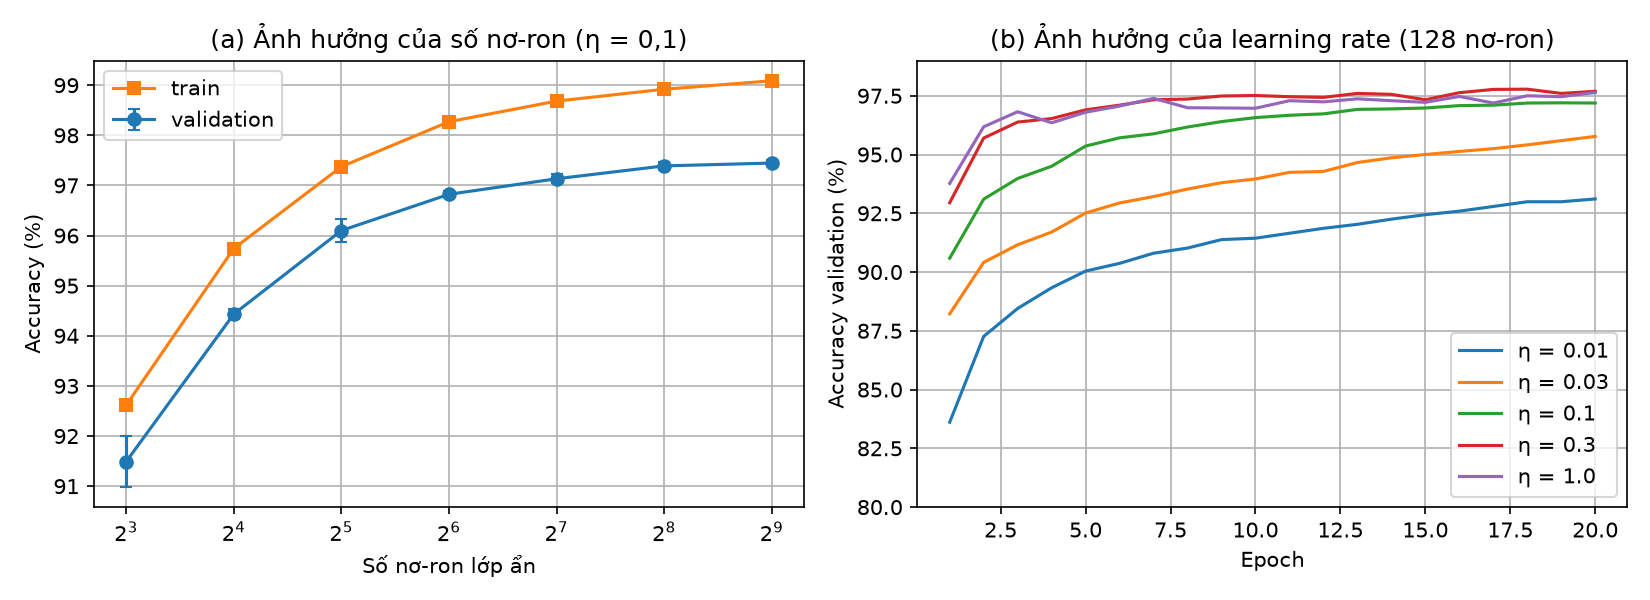

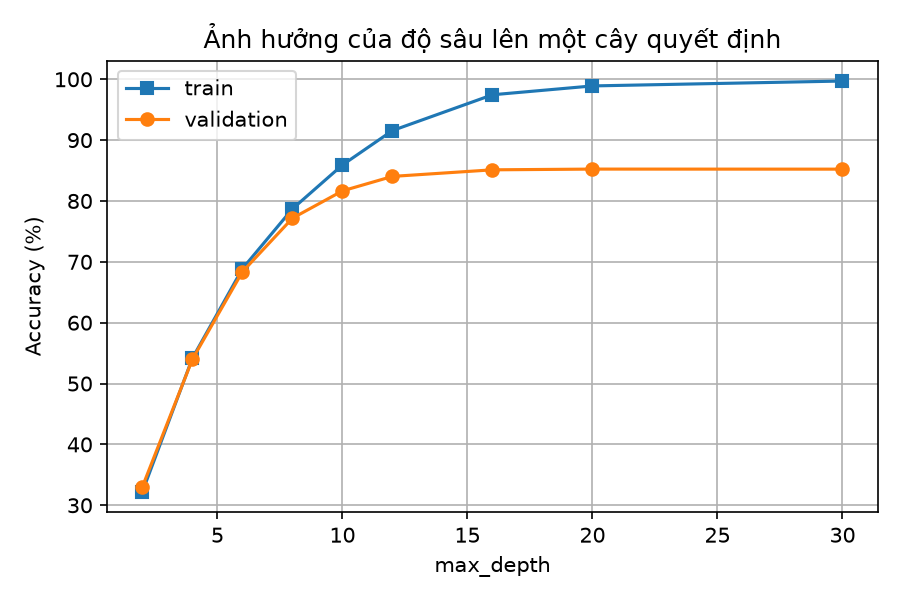

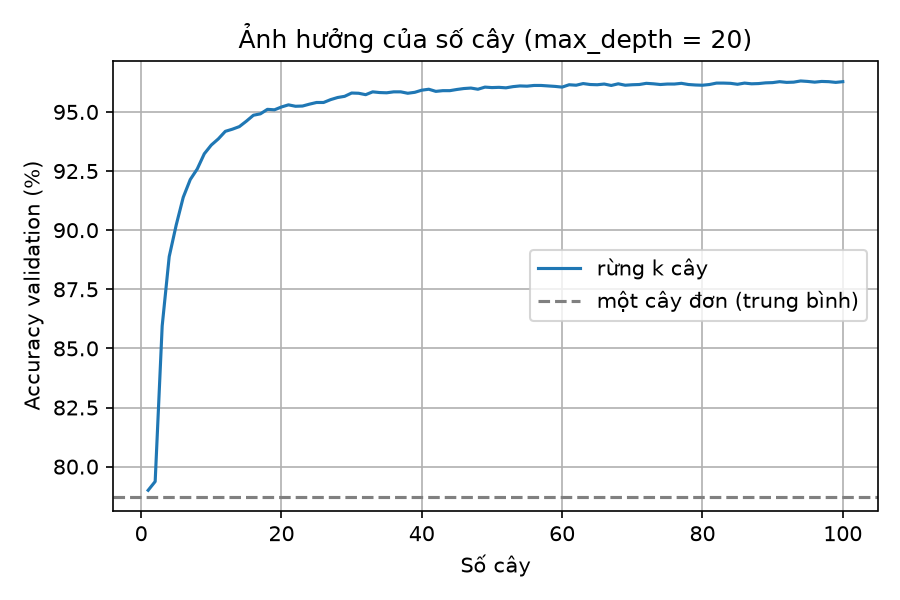

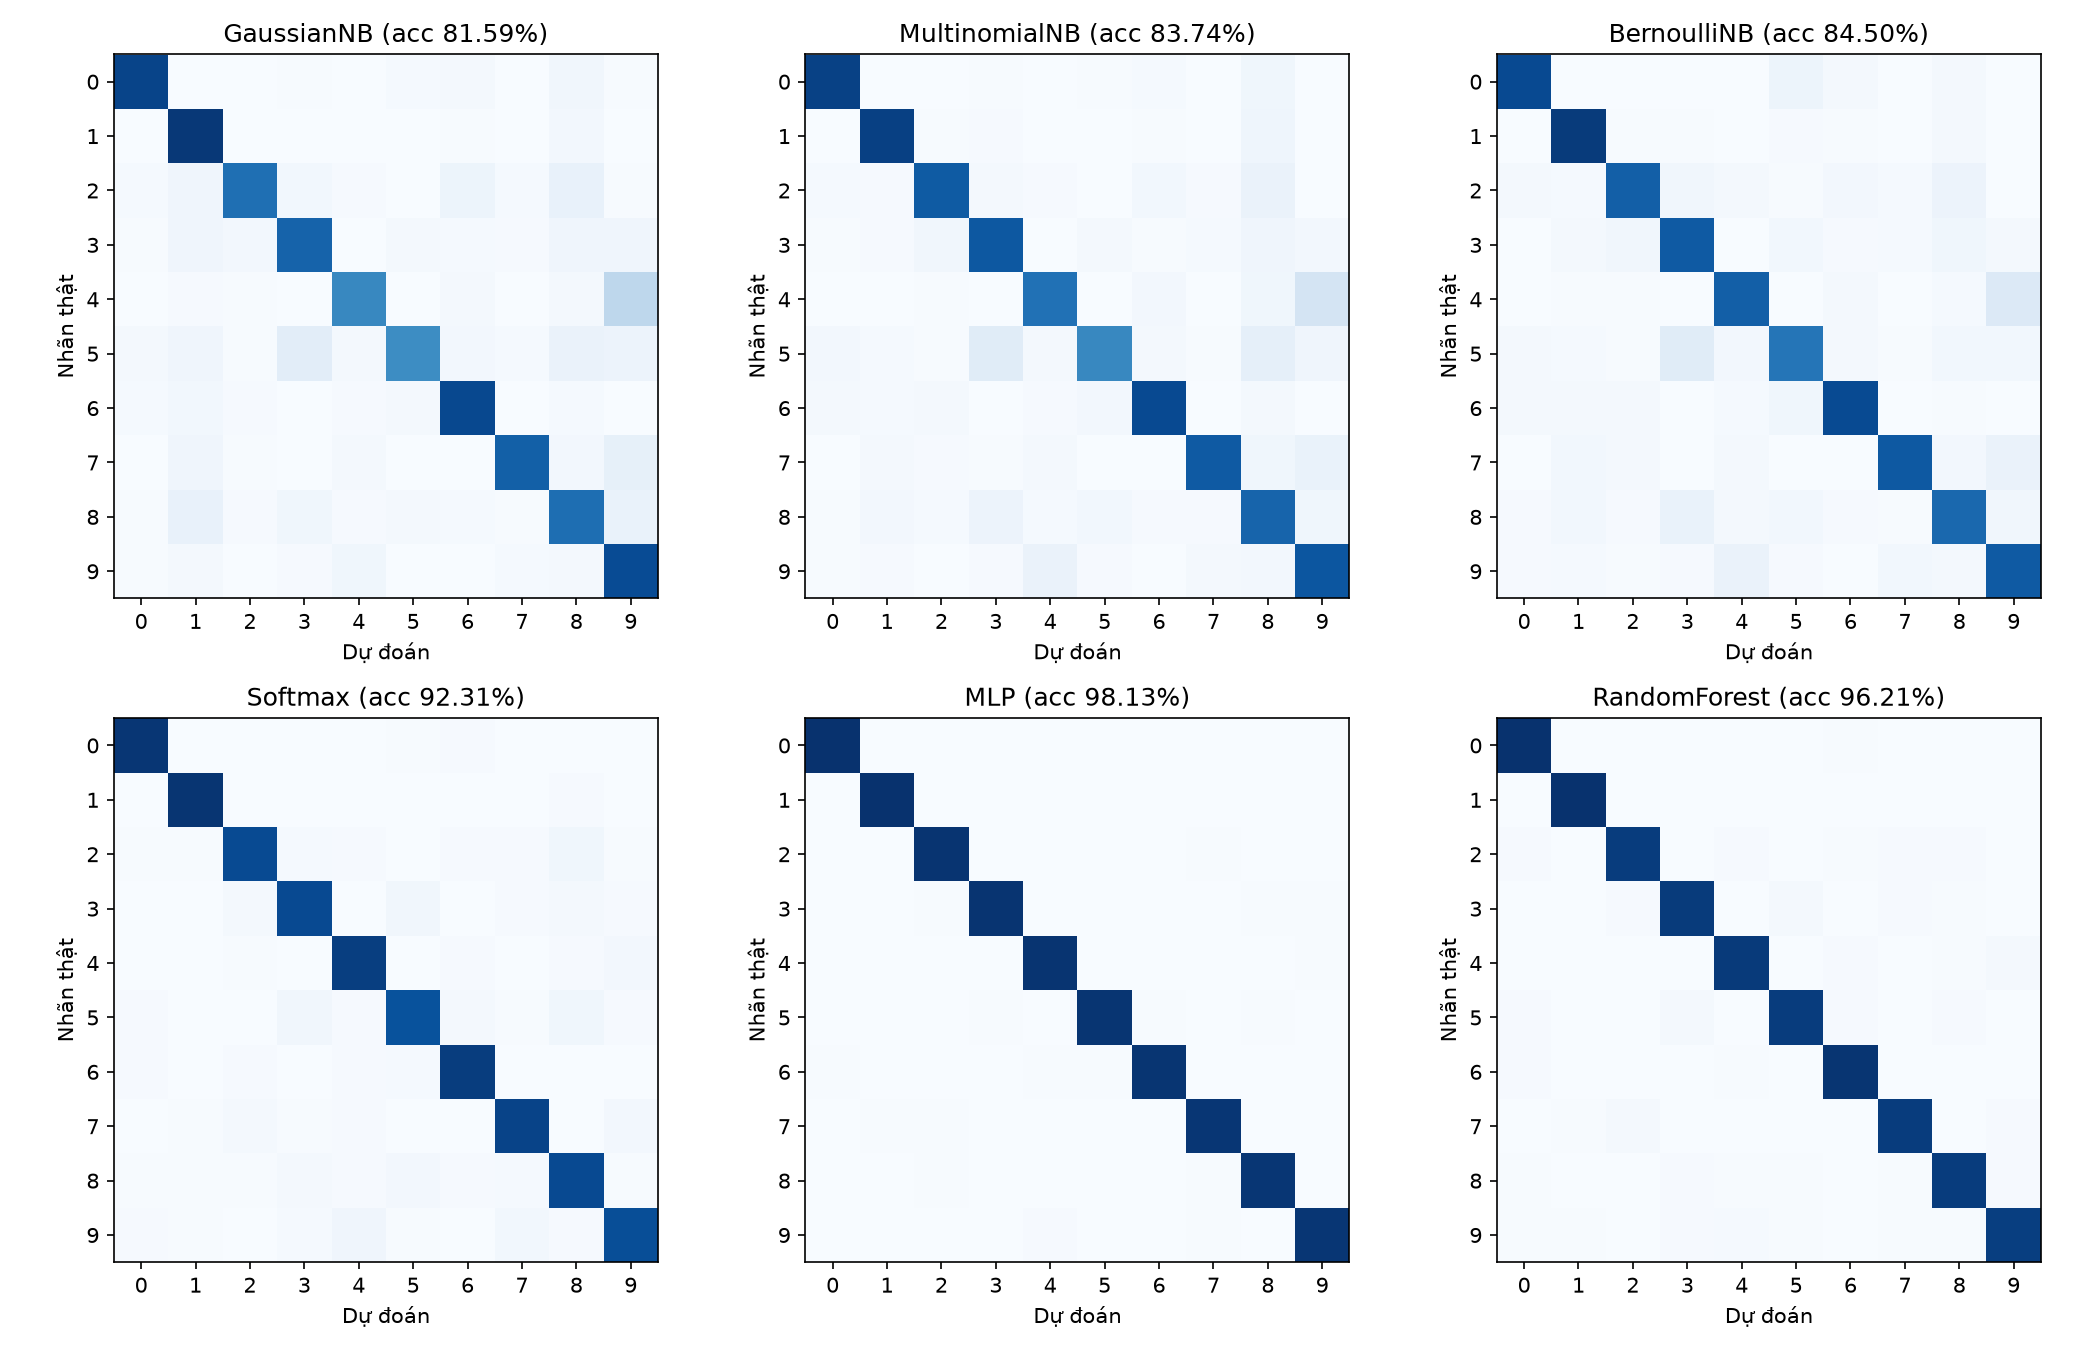

In [4]:
from IPython.display import Image, display
for f in ["mlp_hyper.png", "tree_depth.png", "forest_trees.png", "confusion_test_all.png"]:
    display(Image(filename=str(p / "report" / f)))